# ML Homework 07: k-NN Classification and K-Means Clustering

## Описание

В этом задании вам предстоит реализовать два фундаментальных алгоритма машинного обучения:
1. **k-NN (k Nearest Neighbors)** — метод k ближайших соседей для классификации
2. **K-Means** — алгоритм кластеризации

Вы научитесь:
1. Работать с метриками расстояния (L1, L2)
2. Реализовывать ленивое обучение (lazy learning)
3. Понимать механику EM-алгоритма на примере K-Means
4. Визуализировать границы решений и результаты кластеризации
5. Использовать PCA и t-SNE для понижения размерности

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_blobs, load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier as SklearnKNN
from sklearn.cluster import KMeans as SklearnKMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, silhouette_score
import ipytest
import pytest

%matplotlib inline
plt.style.use('default')
np.random.seed(42)

---

## Теоретическая часть

### k-Nearest Neighbors (k-NN)

**Основная идея:** Для классификации нового объекта найдем k ближайших к нему объектов из обучающей выборки и выберем самый популярный класс среди них.

**Метрики расстояния:**
- L1 (Манхэттенское): $d_1(x, x') = \sum_{j=1}^p |x_j - x'_j|$
- L2 (Евклидово): $d_2(x, x') = \sqrt{\sum_{j=1}^p (x_j - x'_j)^2}$

**Алгоритм классификации:**
1. Для каждого тестового объекта вычислить расстояния до всех обучающих объектов
2. Найти k объектов с минимальными расстояниями
3. Провести голосование по классам этих k соседей
4. При ничьей — выбрать класс с минимальной суммой расстояний

**Weighted k-NN:** Каждый сосед голосует с весом $w_i = \frac{1}{d(x, x_i) + \epsilon}$, где $\epsilon$ — малое число для избежания деления на ноль.

### Проклятие размерности (Curse of Dimensionality)

**Проблема:** С ростом числа признаков (размерности) расстояния между точками теряют смысл, и качество k-NN резко падает.

**Математическое объяснение:**

Рассмотрим единичный гиперкуб в $d$-мерном пространстве $[0, 1]^d$:
- **Объем** гиперкуба: $V_d = 1^d = 1$
- **Объем** гипершара радиуса $r$: $V_{sphere} = \frac{\pi^{d/2}}{\Gamma(d/2 + 1)} r^d$

При увеличении размерности $d$:
- При фиксированном радиусе объем гипершара стремится к 0 относительно объема единичного гиперкуба
- Точки становятся "эквидистантными" (равноудаленными друг от друга)
- Расстояние до ближайшего соседа приближается к расстоянию до дальнего

**Последствия для k-NN:**

Концентрация расстояний возникает при определённых предположениях о данных (например, много независимых сопоставимых по масштабу признаков); это не универсальное утверждение для любых высокомерных данных.

1. **Потеря различимости:** В высоких размерностях все точки почти одинаково далеко друг от друга
   $$ \lim_{d \to \infty} \frac{\max_i d_i - \min_i d_i}{\min_i d_i} \to 0 $$

2. **Разреженность данных:** Для покрытия пространства требуется экспоненциально больше данных
   - В 1D: 100 точек покрывают отрезок хорошо
   - В 10D: $100^{10}$ точек нужно для аналогичной плотности

3. **Шумовые признаки:** Нерелевантные признаки доминируют над информативными
   - Если 8 из 10 признаков шумовые, они могут доминировать в расстоянии; точная доля зависит от их масштаба и распределения

**Визуализация эффекта:**

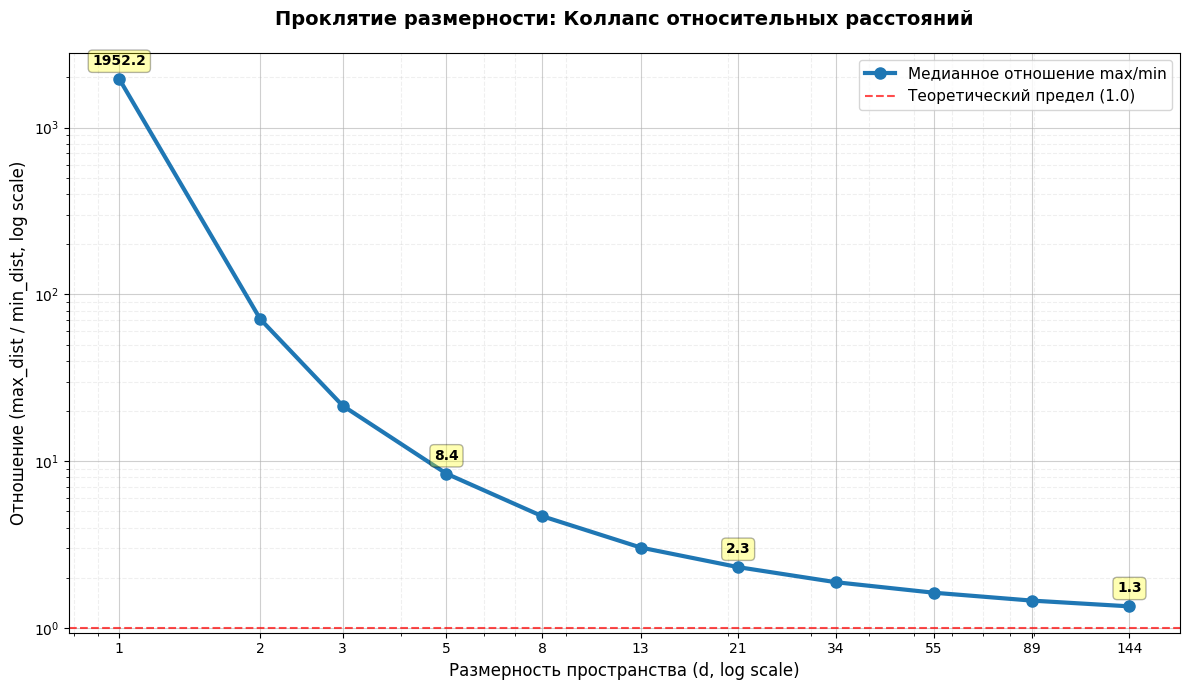

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import pairwise_distances

# Подбор размерностей для более плавного графика
dims = [1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144]
ratio_stats = []

for d in dims:
    # Генерируем 1000 точек в d-мерном единичном кубе
    points = np.random.rand(1000, d)

    # Векторизованный расчёт попарных расстояний
    distances = pairwise_distances(points, metric="euclidean")

    # Исключаем диагональ
    masked_distances = distances.copy()
    np.fill_diagonal(masked_distances, np.inf)

    min_d = np.min(masked_distances, axis=1)
    max_d = np.max(distances, axis=1)

    # Отношение показывает, насколько "размазаны" расстояния
    # Используем медиану для большей устойчивости к выбросам в малых размерностях
    ratio = np.median(max_d / (min_d + 1e-10))
    ratio_stats.append(ratio)

plt.figure(figsize=(12, 7))

# Используем логарифмический масштаб для обеих осей, так как значения падают экспоненциально
plt.yscale("log")
plt.xscale("log")

# Основная линия и точки
plt.plot(
    dims,
    ratio_stats,
    marker="o",
    markersize=8,
    linewidth=3,
    color="#1f77b4",
    label="Медианное отношение max/min",
)

# Аннотации для ключевых точек
for i, (d, r) in enumerate(zip(dims, ratio_stats)):
    if d in [1, 5, 21, 144]:
        plt.annotate(
            f"{r:.1f}",
            (d, r),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3),
        )

plt.xlabel("Размерность пространства (d, log scale)", fontsize=12)
plt.ylabel("Отношение (max_dist / min_dist, log scale)", fontsize=12)
plt.title("Проклятие размерности: Коллапс относительных расстояний", fontsize=14, fontweight="bold", pad=20)

# Настройка сетки
plt.grid(True, which="major", ls="-", alpha=0.6)
plt.grid(True, which="minor", ls="--", alpha=0.2)

# Линия предела
plt.axhline(1, color="red", linestyle="--", alpha=0.7, label="Теоретический предел (1.0)")

# Установка явных тиков для размерностей
plt.xticks(dims, dims)

plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

**Решения проблемы:**
- **Feature Selection:** оставить только важные признаки
- **Dimensionality Reduction:** PCA; t-SNE обычно применяют для визуализации, а не как стандартную предобработку k-NN
- **Distance Weighting:** придать больший вес информативным признакам
- **Нормализация:** масштабировать признаки перед вычислением расстояний
- **Оговорка:** Универсального правила вида $d \ll \log n$ нет: качество зависит от внутренней размерности, шума и структуры данных.

**Интуиция:** Представьте комнату (3D) — легко найти ближайшего человека. Теперь представьте 100-мерное пространство — понятие "близости" теряет смысл, все точки оказываются примерно на одинаковом расстоянии друг от друга.

### K-Means Clustering

**Основная идея:** Разбить n объектов на k кластеров так, чтобы минимизировать сумму квадратов расстояний от объектов до центроидов их кластеров.

**Целевая функция:**
$$J = \sum_{i=1}^n \sum_{j=1}^k r_{ij} \|x_i - \mu_j\|^2$$

где $r_{ij} = 1$ если объект $i$ принадлежит кластеру $j$, иначе 0.

**Алгоритм:**
1. **Инициализация:** Случайно выбрать k точек как начальные центроиды
2. **E-step (Expectation):** Назначить каждую точку ближайшему центроиду
3. **M-step (Maximization):** Пересчитать центроиды как среднее точек кластера
4. **Повторять** шаги 2-3 пока центроиды не перестанут изменяться или не достигнут max_iterations

### Понижение размерности

**Зачем нужно:**
- Визуализация высокомерных данных
- Ускорение алгоритмов
- Удаление шума
- **Борьба с проклятием размерности**

**Методы:**
- **PCA (Principal Component Analysis):** Линейный метод, находит ортогональные направления максимальной дисперсии
- **t-SNE:** Нелинейный метод, сохраняет локальную структуру данных

В этой лабораторной работе мы будем использовать готовые реализации из sklearn для визуализации данных.

**Уточнения:** K-Means — алгоритм Ллойда с жёстким назначением кластеров; его шаги похожи на EM, но он не вычисляет мягкие вероятности принадлежности. PCA сохраняет максимальную дисперсию, а не гарантированно классы или кластеры. t-SNE показывает главным образом локальные соседства; расстояния между отдельными группами на картинке нужно трактовать осторожно.


---

## Часть 1: k-NN Классификация

### Задание 1: Метрики расстояния

Реализуйте функции для вычисления L1 (манхэттенского) и L2 (евклидового) расстояний между двумя векторами.

In [3]:
def l1_distance(x1, x2):
    """
    Вычислить манхэттенское расстояние между двумя векторами.

    d1(x, x') = sum(|xj - x'j|)

    Parameters:
    -----------
    x1, x2 : numpy arrays одинаковой размерности

    Returns:
    --------
    distance : float - манхэттенское расстояние
    """
    #TODO: Реализовать функцию
    return float(np.sum(np.abs(np.asarray(x1, dtype=float) - np.asarray(x2, dtype=float))))


def l2_distance(x1, x2):
    """
    Вычислить евклидово расстояние между двумя векторами.

    d2(x, x') = sqrt(sum((xj - x'j)^2))

    Parameters:
    -----------
    x1, x2 : numpy arrays одинаковой размерности

    Returns:
    --------
    distance : float - евклидово расстояние
    """
    #TODO: Реализовать функцию
    return float(np.linalg.norm(np.asarray(x1, dtype=float) - np.asarray(x2, dtype=float)))


### Задание 2: Вычисление матрицы расстояний

Реализуйте функцию для эффективного вычисления матрицы расстояний между всеми парами точек из двух наборов данных используя broadcasting.

In [4]:
def compute_distances(X_train, X_test, metric="l2"):
    """
    Вычислить матрицу расстояний между всеми парами точек.

    Используйте numpy broadcasting для эффективности.

    Parameters:
    -----------
    X_train : numpy array shape (n_train, n_features)
    X_test : numpy array shape (n_test, n_features)
    metric : 'l1' или 'l2'

    Returns:
    --------
    distances : numpy array shape (n_test, n_train)
                  distances[i, j] = расстояние между X_test[i] и X_train[j]
    """
    #TODO: Реализовать с помощью broadcasting
    # Подсказка: используйте np.linalg.norm для L2 и np.sum(np.abs(...)) для L1
    # Или используйте формулу: ||a-b||^2 = ||a||^2 + ||b||^2 - 2*a*b
    X_train = np.asarray(X_train, dtype=float)
    X_test = np.asarray(X_test, dtype=float)
    if X_train.ndim != 2 or X_test.ndim != 2 or X_train.shape[1] != X_test.shape[1]:
        raise ValueError("Ожидаются двумерные массивы с одинаковым числом признаков")
    diff = X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :]
    if metric == "l2":
        return np.linalg.norm(diff, axis=2)
    if metric == "l1":
        return np.sum(np.abs(diff), axis=2)
    raise ValueError("metric должна быть 'l1' или 'l2'")


### Задание 3: Класс KNNClassifier

Реализуйте класс k-NN для классификации с поддержкой:
- Выбора количества соседей (n_neighbors)
- Выбора метрики расстояния (metric)
- Взвешенного голосования (weights)

In [5]:
class KNNClassifier:
    def __init__(self, n_neighbors=5, metric="l2", weights="uniform"):
        """
        K-Nearest Neighbors классификатор.

        Parameters:
        -----------
        n_neighbors : int - количество соседей (по умолчанию 5)
        metric : 'l1' или 'l2' - метрика расстояния (по умолчанию 'l2')
        weights : 'uniform' или 'distance' - схема взвешивания (по умолчанию 'uniform')
        """
        self.n_neighbors = n_neighbors
        self.metric = metric
        self.weights = weights
        self.X_train = None
        self.y_train = None
        self.classes_ = None

    def fit(self, X, y):
        """
        Обучить модель (lazy learning - просто сохранить данные).

        Parameters:
        -----------
        X : numpy array shape (n_samples, n_features)
        y : numpy array shape (n_samples,)
        """
        #TODO: Сохранить обучающие данные и уникальные классы
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
            raise ValueError("X должен быть непустой двумерной матрицей")
        if y.ndim != 1 or len(y) != len(X):
            raise ValueError("Нужна одна метка на каждый обучающий объект")
        if not isinstance(self.n_neighbors, (int, np.integer)) or not 1 <= self.n_neighbors <= len(X):
            raise ValueError("n_neighbors должен быть целым числом от 1 до n_samples")
        if self.metric not in ("l1", "l2") or self.weights not in ("uniform", "distance"):
            raise ValueError("Неверная метрика или схема голосования")
        if not np.isfinite(X).all():
            raise ValueError("Признаки должны быть конечными числами")
        self.X_train = X.copy()
        self.y_train = y.copy()
        self.classes_ = np.unique(y)
        return self

    def _validate_X(self, X):
        if self.X_train is None:
            raise ValueError("Сначала вызовите fit")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.X_train.shape[1] or not np.isfinite(X).all():
            raise ValueError("Неверная форма X или неконечные значения")
        return X

    def _neighbor_votes(self, x):
        """Общая логика соседей для predict и predict_proba."""
        distances = compute_distances(self.X_train, np.asarray(x)[None, :], self.metric)[0]
        indices = np.argpartition(distances, self.n_neighbors - 1)[:self.n_neighbors]
        neighbor_distances = distances[indices]
        labels = self.y_train[indices]
        weights = (np.ones(self.n_neighbors) if self.weights == "uniform"
                   else 1.0 / (neighbor_distances + 1e-9))
        scores = np.array([weights[labels == cls].sum() for cls in self.classes_])
        distance_sums = np.array([neighbor_distances[labels == cls].sum() for cls in self.classes_])
        return scores, distance_sums

    def predict(self, X):
        """
        Предсказать классы для всех образцов.

        Parameters:
        -----------
        X : numpy array shape (n_samples, n_features)

        Returns:
        --------
        predictions : numpy array shape (n_samples,)
        """
        #TODO: Реализовать предсказание для всех образцов
        X = self._validate_X(X)
        return np.array([self._predict_single(x) for x in X], dtype=self.y_train.dtype)

    def predict_proba(self, X):
        """
        Предсказать вероятности классов для всех образцов.

        Parameters:
        -----------
        X : numpy array shape (n_samples, n_features)

        Returns:
        --------
        proba : numpy array shape (n_samples, n_classes)
        """
        #TODO: Реализовать предсказание вероятностей
        X = self._validate_X(X)
        return np.array([self._predict_proba_single(x) for x in X]).reshape(len(X), len(self.classes_))

    def _predict_single(self, x):
        """
        Предсказать класс для одного образца.
        """
        #TODO: Реализовать предсказание для одного образца
        # 1. Вычислить расстояния до всех обучающих точек
        # 2. Найти индексы k ближайших соседей (используйте np.argpartition)
        # 3. Получить классы соседей и их расстояния
        # 4. Провести голосование (с учетом весов если weights='distance')
        # 5. При ничьей выбрать класс с минимальной суммой расстояний
        self._validate_X(np.asarray(x)[None, :])
        scores, distance_sums = self._neighbor_votes(x)
        candidates = np.flatnonzero(scores == scores.max())
        # При равных голосах — минимальная сумма расстояний.
        # Если равны и суммы, выбираем первый класс в classes_.
        best = candidates[np.argmin(distance_sums[candidates])]
        return self.classes_[best]

    def _predict_proba_single(self, x):
        """
        Предсказать вероятности классов для одного образца.
        """
        #TODO: Реализовать вычисление вероятностей
        # Вернуть массив вероятностей для каждого класса
        self._validate_X(np.asarray(x)[None, :])
        scores, _ = self._neighbor_votes(x)
        return scores / scores.sum()


### Визуализация границ решений

Функция для визуализации границы принятия решений на 2D данных.

In [6]:
def plot_decision_boundary(model, X, y, title="Decision Boundary"):
    """
    Визуализировать границу принятия решений для 2D данных.
    """
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="RdYlBu")
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlBu", edgecolor="k", s=50)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.colorbar(scatter)
    plt.show()

### Тестирование k-NN на синтетических данных

In [7]:
# Генерация простых 2D данных для визуализации
X_simple, y_simple = make_classification(
    n_samples=200, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=2, random_state=42
)

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y_simple, test_size=0.3, random_state=42
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (140, 2), Test shape: (60, 2)


In [8]:
# Обучение вашей модели
knn = KNNClassifier()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(f"Accuracy (My KNN): {accuracy_score(y_test, y_pred):.4f}")

# Сравнение со sklearn
sk_knn = SklearnKNN()
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

print(f"Accuracy (Sklearn): {accuracy_score(y_test, y_pred_sk):.4f}")

Accuracy (My KNN): 0.8333
Accuracy (Sklearn): 0.8333


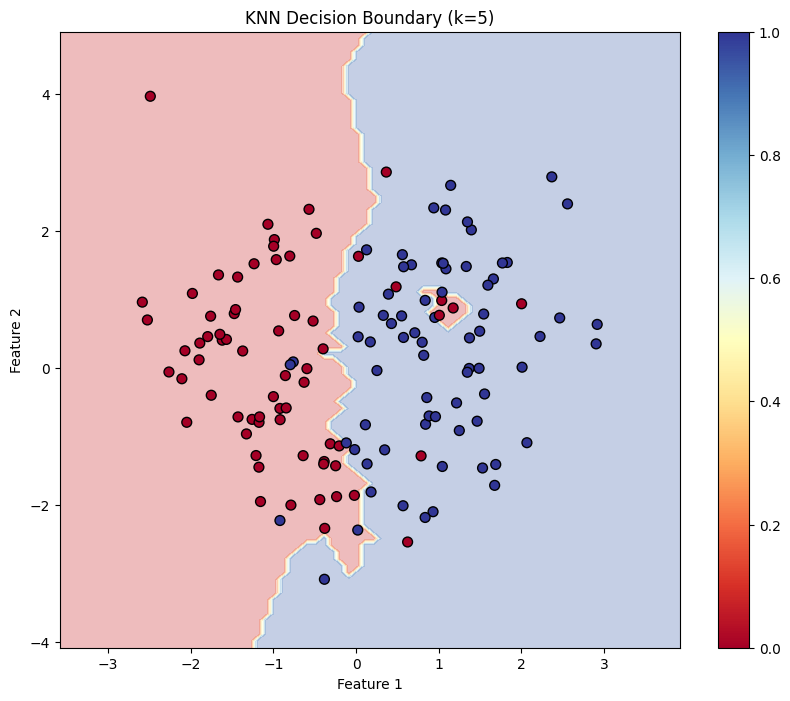

In [9]:
# Визуализация границы решений
plot_decision_boundary(knn, X_train, y_train, f"KNN Decision Boundary (k={knn.n_neighbors})")

In [10]:
# Сравнение uniform vs distance weights
knn_uniform = KNNClassifier(n_neighbors=5, weights='uniform')
knn_distance = KNNClassifier(n_neighbors=5, weights='distance')

knn_uniform.fit(X_train, y_train)
knn_distance.fit(X_train, y_train)

acc_uniform = accuracy_score(y_test, knn_uniform.predict(X_test))
acc_distance = accuracy_score(y_test, knn_distance.predict(X_test))

print(f"Accuracy (uniform weights): {acc_uniform:.4f}")
print(f"Accuracy (distance weights): {acc_distance:.4f}")

Accuracy (uniform weights): 0.8333
Accuracy (distance weights): 0.8333


### Тесты (ipytest)

In [11]:
ipytest.autoconfig()


class TestKNN:
    def test_l1_distance(self):
        """Тест L1 расстояния"""
        x1 = np.array([1, 2, 3])
        x2 = np.array([2, 3, 4])
        expected = 3  # |1-2| + |2-3| + |3-4| = 1 + 1 + 1 = 3
        assert l1_distance(x1, x2) == expected

    def test_l2_distance(self):
        """Тест L2 расстояния"""
        x1 = np.array([0, 0])
        x2 = np.array([3, 4])
        expected = 5  # sqrt(3^2 + 4^2) = 5
        assert np.isclose(l2_distance(x1, x2), expected)

    def test_simple_classification(self):
        """Тест классификации на простых данных"""
        # Два хорошо разделенных кластера
        X = np.array(
            [
                [0, 0],
                [0, 1],
                [1, 0],
                [1, 1],  # класс 0
                [10, 10],
                [10, 11],
                [11, 10],
                [11, 11],
            ]
        )  # класс 1
        y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

        knn = KNNClassifier(n_neighbors=3, metric="l2")
        knn.fit(X, y)

        # Тестируем точки рядом с кластерами
        assert knn._predict_single(np.array([0.5, 0.5])) == 0
        assert knn._predict_single(np.array([10.5, 10.5])) == 1

    def test_tie_breaking(self):
        """Тест разрывания связей"""
        # Точка равноудалена от двух классов
        X = np.array(
            [
                [0, 0],
                [0, 2],  # класс 0
                [2, 0],
                [2, 2],
            ]
        )  # класс 1
        y = np.array([0, 0, 1, 1])

        knn = KNNClassifier(n_neighbors=2, metric="l2")
        knn.fit(X, y)

        # Точка [1, 1] равноудалена от всех четырех точек
        # Должна выбрать класс с минимальной суммой расстояний
        prediction = knn._predict_single(np.array([1, 1]))
        assert prediction in [0, 1]  # Должен выбрать один из классов

    def test_predict_proba(self):
        """Тест предсказания вероятностей"""
        X = np.array(
            [
                [0, 0],
                [0, 1],  # класс 0
                [10, 10],
                [10, 11],
            ]
        )  # класс 1
        y = np.array([0, 0, 1, 1])

        knn = KNNClassifier(n_neighbors=2, metric="l2")
        knn.fit(X, y)

        proba = knn._predict_proba_single(np.array([0.5, 0.5]))
        assert len(proba) == 2  # Два класса
        assert np.isclose(proba.sum(), 1.0)  # Сумма вероятностей = 1
        assert proba[0] > proba[1]  # Ближе к классу 0


ipytest.run("-q", raise_on_error=True)

.

.

.

.

.

                                                                                        [100%]

<ExitCode.OK: 0>

---

## Часть 2: Понижение размерности

В этой части мы используем готовые реализации PCA и t-SNE из sklearn для визуализации данных перед кластеризацией.

In [12]:
# Загрузка датасета Iris (4 признака, 3 класса)
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Iris dataset shape: {X_iris.shape}")
print(f"Features: {feature_names}")
print(f"Classes: {target_names}")

Iris dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


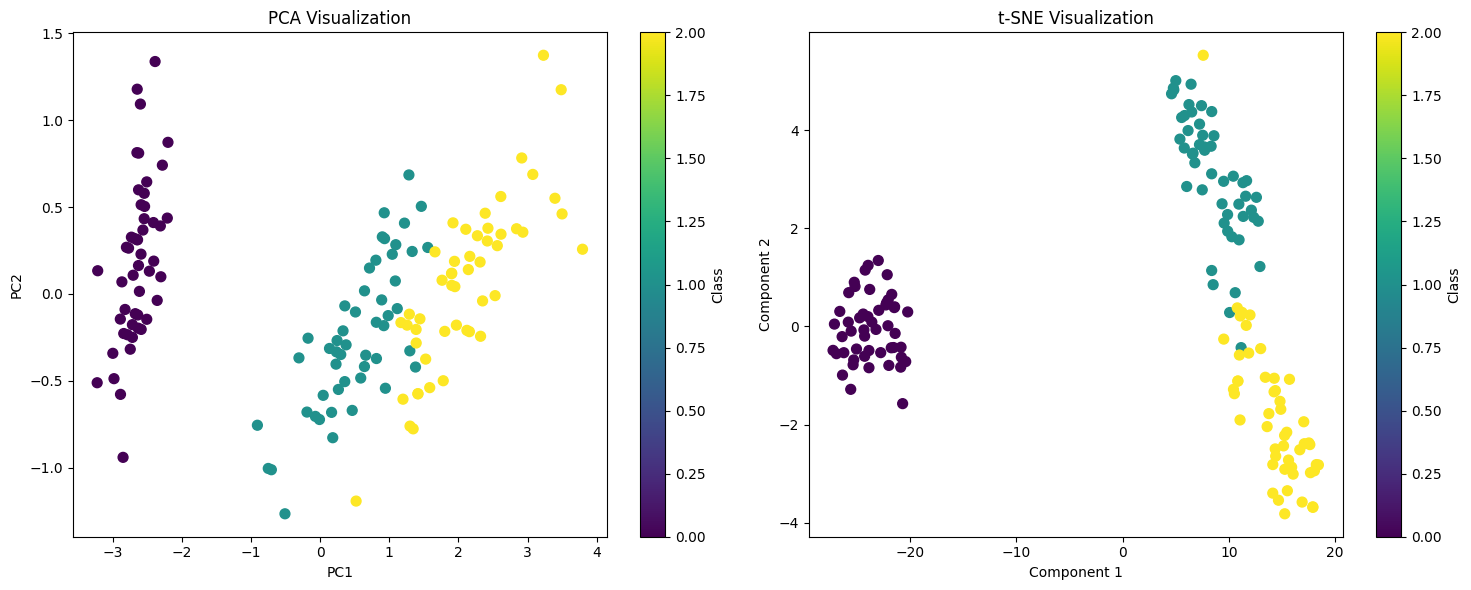

PCA explained variance ratio: [0.92461872 0.05306648]
Total explained variance: 0.9777


In [13]:
# Применение PCA
pca = PCA(n_components=2)
X_iris_pca = pca.fit_transform(X_iris)

# Применение t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_iris_tsne = tsne.fit_transform(X_iris)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PCA
scatter1 = axes[0].scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=y_iris, cmap='viridis', s=50)
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('PCA Visualization')
plt.colorbar(scatter1, ax=axes[0], label='Class')

# t-SNE
scatter2 = axes[1].scatter(X_iris_tsne[:, 0], X_iris_tsne[:, 1], c=y_iris, cmap='viridis', s=50)
axes[1].set_xlabel('Component 1')
axes[1].set_ylabel('Component 2')
axes[1].set_title('t-SNE Visualization')
plt.colorbar(scatter2, ax=axes[1], label='Class')

plt.tight_layout()
plt.show()

print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.4f}")

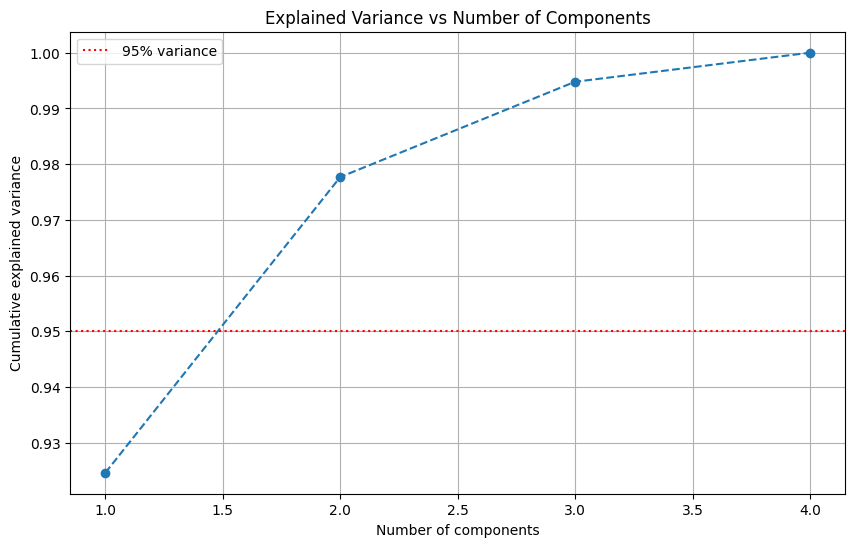

In [14]:
# График explained variance для разного числа компонент
pca_full = PCA()
pca_full.fit(X_iris)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         np.cumsum(pca_full.explained_variance_ratio_),
         marker='o', linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Explained Variance vs Number of Components')
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle=':', label='95% variance')
plt.legend()
plt.show()

---

## Часть 3: K-Means Кластеризация

### Задание 4: Класс KMeansClustering

Реализуйте алгоритм K-Means с нуля.

In [15]:
class KMeansClustering:
    def __init__(self, n_clusters=3, max_iterations=100, tol=1e-4, random_state=None):
        """
        K-Means кластеризация.

        Parameters:
        -----------
        n_clusters : int - количество кластеров
        max_iterations : int - максимальное число итераций
        tol : float - порог сходимости (изменение центроидов)
        random_state : int - для воспроизводимости
        """
        # Для сохранения истории центроидов
        self.n_clusters = n_clusters
        self.max_iterations = max_iterations
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = None
        self.history = []
        self.n_iter_ = 0

    def fit(self, X):
        """
        Обучить модель кластеризации.

        Parameters:
        -----------
        X : numpy array shape (n_samples, n_features)
        """
        #TODO: Реализовать основной алгоритм
        # 1. Инициализировать центроиды
        # 2. Повторять max_iterations раз:
        #    a. Назначить точки ближайшим центроидам (E-step)
        #    b. Пересчитать центроиды как среднее (M-step)
        #    c. Проверить сходимость
        # 3. Вычислить финальную inertia
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0 or not np.isfinite(X).all():
            raise ValueError("X должен быть непустой конечной двумерной матрицей")
        if not isinstance(self.n_clusters, (int, np.integer)) or not 1 <= self.n_clusters <= len(X):
            raise ValueError("n_clusters должен быть целым числом от 1 до n_samples")
        if not isinstance(self.max_iterations, (int, np.integer)) or self.max_iterations < 1:
            raise ValueError("max_iterations должен быть положительным целым числом")
        if not np.isfinite(self.tol) or self.tol < 0:
            raise ValueError("tol должен быть конечным неотрицательным числом")
        self.centroids = self._initialize_centroids(X)
        self.history = [self.centroids.copy()]
        self.n_iter_ = 0
        for iteration in range(self.max_iterations):
            labels = self._assign_clusters(X)
            new_centroids = self._update_centroids(X, labels)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.history.append(self.centroids.copy())
            self.n_iter_ = iteration + 1
            if shift <= self.tol:
                break
        # Метки и inertia должны соответствовать последним центроидам.
        self.labels_ = self._assign_clusters(X)
        self.inertia_ = self._compute_inertia(X)
        return self

    def predict(self, X):
        """
        Назначить кластеры для новых данных.

        Parameters:
        -----------
        X : numpy array shape (n_samples, n_features)

        Returns:
        --------
        labels : numpy array shape (n_samples,)
        """
        #TODO: Реализовать предсказание кластеров
        if self.centroids is None:
            raise ValueError("Сначала вызовите fit")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.centroids.shape[1] or not np.isfinite(X).all():
            raise ValueError("Неверная форма X или неконечные значения")
        return self._assign_clusters(X)

    def _initialize_centroids(self, X):
        """
        Инициализировать центроиды случайным выбором из данных.
        """
        #TODO: Реализовать случайную инициализацию
        rng = np.random.default_rng(self.random_state)
        indices = rng.choice(len(X), size=self.n_clusters, replace=False)
        return X[indices].copy()

    def _assign_clusters(self, X):
        """
        E-step: назначить каждую точку ближайшему центроиду.
        """
        #TODO: Реализовать назначение кластеров
        # Подсказка: вычислить расстояния до всех центроидов, выбрать минимальный
        squared_distances = np.sum((X[:, None, :] - self.centroids[None, :, :]) ** 2, axis=2)
        return np.argmin(squared_distances, axis=1)

    def _update_centroids(self, X, labels):
        """
        M-step: обновить центроиды как среднее точек кластера.
        """
        #TODO: Реализовать обновление центроидов
        # Обработка пустых кластеров: сохранить старый центроид
        centroids = self.centroids.copy()
        for cluster in range(self.n_clusters):
            points = X[labels == cluster]
            if len(points):
                centroids[cluster] = points.mean(axis=0)
            # Для пустого кластера оставляем старый центроид.
        return centroids

    def _compute_inertia(self, X):
        """
        Вычислить сумму квадратов расстояний до ближайших центроидов.
        """
        #TODO: Реализовать вычисление inertia
        labels = self._assign_clusters(X)
        return float(np.sum((X - self.centroids[labels]) ** 2))


### Визуализация K-Means

In [16]:
def plot_kmeans_result(X, centroids, labels, title="K-Means Clustering"):
    """
    Визуализировать результаты кластеризации для 2D данных.
    """
    plt.figure(figsize=(10, 8))

    # Отобразить точки с цветами кластеров
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=50, alpha=0.6)

    # Отобразить центроиды
    plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="x", s=200, linewidths=3, label="Centroids")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.legend()
    plt.colorbar(scatter)
    plt.show()

In [17]:
# Генерация данных для кластеризации
X_blobs, y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=1.5, random_state=42)

print(f"Blobs dataset shape: {X_blobs.shape}")

Blobs dataset shape: (300, 2)


K-Means converged after 11 iterations
Final inertia: 6396.2265


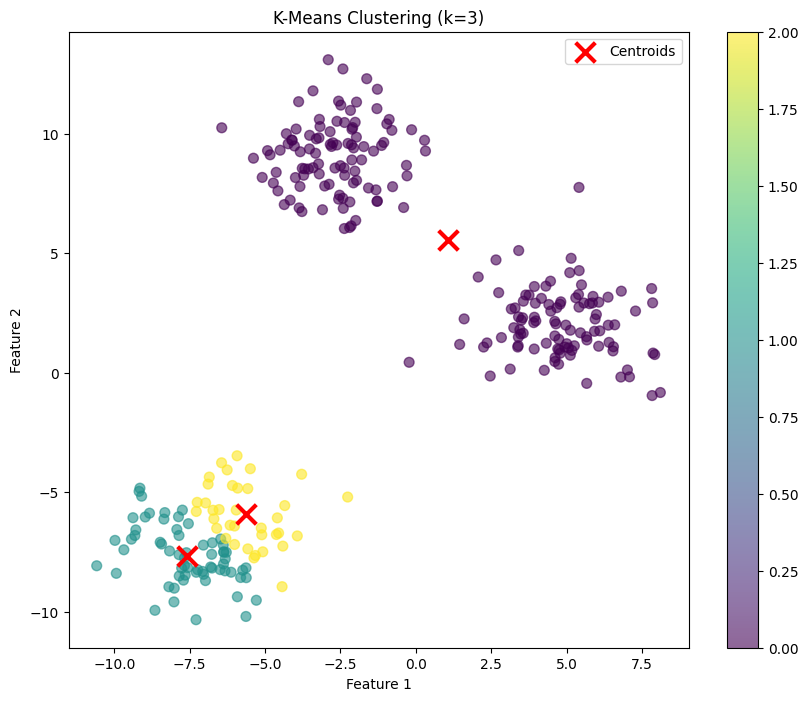

In [18]:
# Обучение вашей модели
kmeans = KMeansClustering(n_clusters=3, random_state=42)
kmeans.fit(X_blobs)

print(f"K-Means converged after {kmeans.n_iter_} iterations")
print(f"Final inertia: {kmeans.inertia_:.4f}")

# Визуализация
plot_kmeans_result(X_blobs, kmeans.centroids, kmeans.labels_, 
                  f"K-Means Clustering (k={kmeans.n_clusters})")

In [19]:
# Сравнение со sklearn
sk_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
sk_kmeans.fit(X_blobs)

print(f"My K-Means inertia: {kmeans.inertia_:.4f}")
print(f"Sklearn inertia: {sk_kmeans.inertia_:.4f}")

My K-Means inertia: 6396.2265
Sklearn inertia: 1275.4340


### Метод локтя для выбора k

In [20]:
def plot_elbow_method(X, max_k=10, random_state=42):
    """
    Построить график метода локтя для выбора оптимального k.
    """
    inertias = []
    K_range = range(1, max_k + 1)

    for k in K_range:
        kmeans = KMeansClustering(n_clusters=k, random_state=random_state)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(10, 6))
    plt.plot(K_range, inertias, marker="o", linestyle="--")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.title("Elbow Method for Optimal k")
    plt.grid(True)
    plt.show()

    return inertias

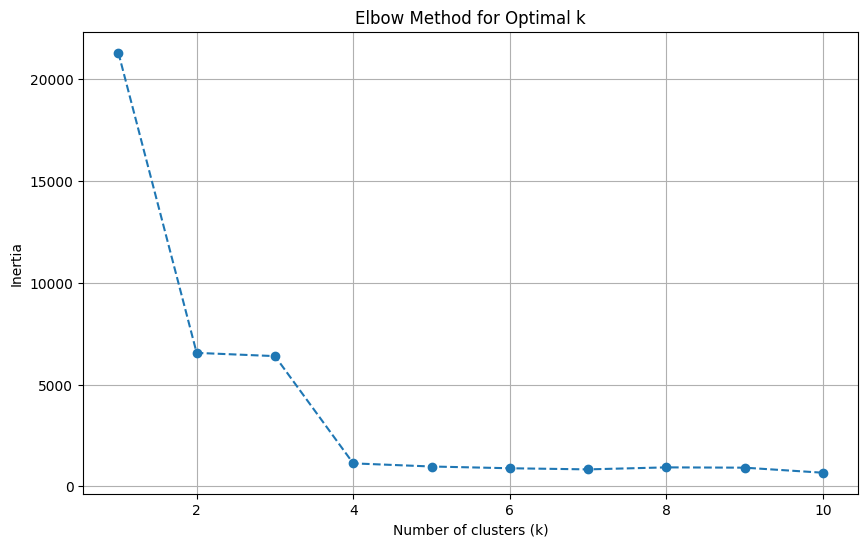

In [21]:
# Применение метода локтя
inertias = plot_elbow_method(X_blobs, max_k=10, random_state=42)

### Тесты (ipytest)

In [22]:
# Должны быть в одном кластере или нет
class TestKMeans:
    def test_simple_clustering(self):
        """Тест на хорошо разделенных кластерах"""
        # Три хорошо разделенных кластера
        X = np.vstack(
            [
                np.random.randn(50, 2) + [0, 0],
                np.random.randn(50, 2) + [10, 0],
                np.random.randn(50, 2) + [0, 10],
            ]
        )

        kmeans = KMeansClustering(n_clusters=3, random_state=42)
        kmeans.fit(X)

        assert kmeans.centroids.shape == (3, 2)
        assert len(kmeans.labels_) == 150
        assert kmeans.inertia_ > 0

    def test_convergence(self):
        """Тест сходимости алгоритма"""
        X = np.random.randn(100, 2)

        kmeans = KMeansClustering(n_clusters=3, max_iterations=50, random_state=42)
        kmeans.fit(X)

        # Проверить, что история содержит не более max_iterations + 1 записей
        assert len(kmeans.history) <= 51  # +1 за начальную инициализацию

    def test_predict_new_data(self):
        """Тест предсказания на новых данных"""
        X = np.vstack([np.random.randn(50, 2) + [0, 0], np.random.randn(50, 2) + [10, 10]])

        kmeans = KMeansClustering(n_clusters=2, random_state=42)
        kmeans.fit(X)

        # Предсказываем для новых точек
        X_new = np.array([[0, 0], [10, 10], [5, 5]])
        labels = kmeans.predict(X_new)

        assert len(labels) == 3
        assert labels[0] != labels[1]  # Точки рядом с разными центрами — разные кластеры

    def test_inertia_monotonic(self):
        """Тест монотонного убывания inertia"""
        X = np.random.randn(100, 2)

        kmeans = KMeansClustering(n_clusters=3, random_state=42)
        kmeans.fit(X)

        # Inertia должна монотонно убываться
        inertias = []
        for centroids in kmeans.history:
            # Вычисляем inertia для данных центроидов
            temp_kmeans = KMeansClustering(n_clusters=3)
            temp_kmeans.centroids = centroids
            temp_kmeans.labels_ = temp_kmeans._assign_clusters(X)
            inertias.append(temp_kmeans._compute_inertia(X))

        for i in range(1, len(inertias)):
            assert inertias[i] <= inertias[i - 1] + 1e-10  # Допускаем небольшую погрешность


ipytest.run("-q", raise_on_error=True)

.

.

.

.

.

.

.

.

.

                                                                                    [100%]

<ExitCode.OK: 0>

---

## Часть 4: Сравнение со Sklearn

### Задание 5: Исследование k-NN

Исследуйте влияние гиперпараметра k на качество классификации.

In [23]:
# Генерация более сложного датасета
X_complex, y_complex = make_classification(
    n_samples=500, n_features=10, n_informative=8, n_redundant=2,
    n_clusters_per_class=2, random_state=42
)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_complex, y_complex, test_size=0.3, random_state=42
)

print(f"Train: {X_train_c.shape}, Test: {X_test_c.shape}")

Train: (350, 10), Test: (150, 10)


k= 1 | My train/test: 1.0000/0.8867 | Sklearn train/test: 1.0000/0.8867
k= 3 | My train/test: 0.9457/0.8933 | Sklearn train/test: 0.9457/0.8933


k= 5 | My train/test: 0.9171/0.8867 | Sklearn train/test: 0.9171/0.8867


k= 7 | My train/test: 0.9029/0.9000 | Sklearn train/test: 0.9029/0.9000
k=11 | My train/test: 0.8943/0.9067 | Sklearn train/test: 0.8943/0.9067


k=15 | My train/test: 0.8743/0.9133 | Sklearn train/test: 0.8743/0.9133


k=21 | My train/test: 0.8743/0.9067 | Sklearn train/test: 0.8743/0.9067
k=31 | My train/test: 0.8457/0.8867 | Sklearn train/test: 0.8457/0.8867


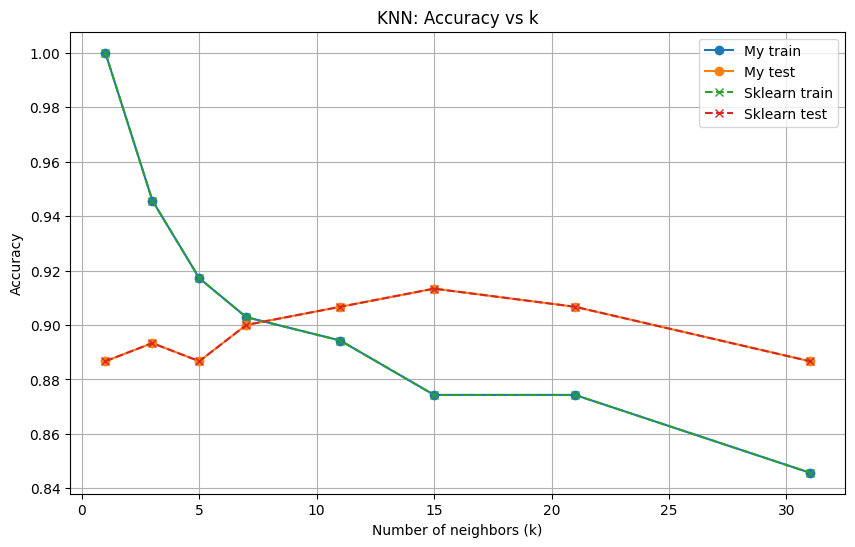

Лучший результат на этом test: k=15, accuracy=0.9133
Для подбора k на практике нужна validation-выборка или cross-validation; test оставляют для итоговой оценки.


In [24]:
#TODO: Исследовать accuracy для разных значений k
#TODO: Обучить вашу модель KNNClassifier и sklearn
# Вычислить accuracy на train и test
# Визуализация
#TODO: Вывести лучшее значение accuracy и соответствующий k
# Сравниваем одинаковые параметры нашей реализации и sklearn.
k_values = [1, 3, 5, 7, 11, 15, 21, 31]
train_acc, test_acc = [], []
sk_train_acc, sk_test_acc = [], []

for k in k_values:
    my_knn = KNNClassifier(n_neighbors=k).fit(X_train_c, y_train_c)
    sk_knn = SklearnKNN(n_neighbors=k).fit(X_train_c, y_train_c)
    train_acc.append(accuracy_score(y_train_c, my_knn.predict(X_train_c)))
    test_acc.append(accuracy_score(y_test_c, my_knn.predict(X_test_c)))
    sk_train_acc.append(accuracy_score(y_train_c, sk_knn.predict(X_train_c)))
    sk_test_acc.append(accuracy_score(y_test_c, sk_knn.predict(X_test_c)))
    print(f"k={k:2d} | My train/test: {train_acc[-1]:.4f}/{test_acc[-1]:.4f} "
          f"| Sklearn train/test: {sk_train_acc[-1]:.4f}/{sk_test_acc[-1]:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(k_values, train_acc, marker='o', label='My train')
plt.plot(k_values, test_acc, marker='o', label='My test')
plt.plot(k_values, sk_train_acc, linestyle='--', marker='x', label='Sklearn train')
plt.plot(k_values, sk_test_acc, linestyle='--', marker='x', label='Sklearn test')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN: Accuracy vs k')
plt.legend()
plt.grid(True)
plt.show()

best_index = int(np.argmax(test_acc))
print(f"Лучший результат на этом test: k={k_values[best_index]}, accuracy={test_acc[best_index]:.4f}")
print("Для подбора k на практике нужна validation-выборка или cross-validation; test оставляют для итоговой оценки.")

### Задание 6: Реальные датасеты

Протестируйте ваши реализации на реальных датасетах.

In [25]:
#TODO: Обучить ваш KNNClassifier и сравнить со sklearn
# 1. Создать две модели
# 2. Обучить их на train
# 3. Посчитать accuracy на test
# 4. Вывести результаты
# K-NN на Iris датасете
iris = load_iris()
X_iris_full = iris.data
y_iris_full = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris_full, y_iris_full, test_size=0.3, random_state=42
)

my_model = KNNClassifier().fit(X_train_iris, y_train_iris)
sklearn_model = SklearnKNN().fit(X_train_iris, y_train_iris)
my_model_acc = accuracy_score(y_test_iris, my_model.predict(X_test_iris))
sklearn_model_acc = accuracy_score(y_test_iris, sklearn_model.predict(X_test_iris))
print(f"Iris — My KNN accuracy: {my_model_acc:.4f}")
print(f"Iris — Sklearn accuracy: {sklearn_model_acc:.4f}")

Iris — My KNN accuracy: 1.0000
Iris — Sklearn accuracy: 1.0000


In [26]:
# K-Means на Wine датасете (unsupervised)
#TODO: Применить ваш KMeansClustering и сравнить со sklearn
# Используйте silhouette_score для оценки качества
#TODO: 1. Создать и обучить две модели
#TODO: 2. Вычислить inertia и silhouette_score
#TODO: 3. Вывести сравнение результатов
# Wine: признаки в разных единицах, поэтому сначала стандартизируем.
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X_wine = StandardScaler().fit_transform(wine.data)
my_wine = KMeansClustering(n_clusters=3, random_state=42).fit(X_wine)
sk_wine = SklearnKMeans(n_clusters=3, random_state=42, n_init=10).fit(X_wine)

for name, labels, inertia in [
    ("My K-Means", my_wine.labels_, my_wine.inertia_),
    ("Sklearn K-Means", sk_wine.labels_, sk_wine.inertia_),
]:
    score = silhouette_score(X_wine, labels)
    print(f"{name}: inertia={inertia:.4f}, silhouette={score:.4f}")
print("Sklearn использует k-means++ и 10 запусков, наша модель — один случайный запуск.")

My K-Means: inertia=1277.9285, silhouette=0.2849
Sklearn K-Means: inertia=1277.9285, silhouette=0.2849
Sklearn использует k-means++ и 10 запусков, наша модель — один случайный запуск.


---

## Итоговые тесты

In [27]:
class TestFinal:
    def test_knn_vs_sklearn_accuracy(self):
        """Тест: ваш KNN должен быть близок к sklearn по качеству"""
        X, y = make_classification(n_samples=200, n_features=5, random_state=42)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

        my_knn = KNNClassifier(n_neighbors=5, metric="l2")
        sk_knn = SklearnKNN(n_neighbors=5)

        my_knn.fit(X_train, y_train)
        sk_knn.fit(X_train, y_train)

        my_acc = accuracy_score(y_test, my_knn.predict(X_test))
        sk_acc = accuracy_score(y_test, sk_knn.predict(X_test))

        # Допускаем отклонение не более 5%
        assert abs(my_acc - sk_acc) < 0.05, (
            f"Ваш KNN сильно отличается от sklearn: {my_acc:.4f} vs {sk_acc:.4f}"
        )

    def test_kmeans_converges(self):
        """Тест: K-Means должен сходиться"""
        X, _ = make_blobs(n_samples=200, centers=4, random_state=42)

        kmeans = KMeansClustering(n_clusters=4, max_iterations=100, random_state=42)
        kmeans.fit(X)

        # Проверить, что нашли именно 4 кластера
        unique_labels = np.unique(kmeans.labels_)
        assert len(unique_labels) <= 4, "Найдено больше кластеров, чем ожидается"

    def test_weighted_knn(self):
        """Тест взвешенного k-NN"""
        X = np.array(
            [
                [0, 0],
                [0.1, 0],  # класс 0, близко к тестовой точке
                [10, 10],
                [10, 11],  # класс 1, далеко
            ]
        )
        y = np.array([0, 0, 1, 1])

        knn_uniform = KNNClassifier(n_neighbors=3, weights="uniform")
        knn_distance = KNNClassifier(n_neighbors=3, weights="distance")

        knn_uniform.fit(X, y)
        knn_distance.fit(X, y)

        # Точка [0.05, 0] ближе к классу 0
        test_point = np.array([0.05, 0])

        pred_uniform = knn_uniform._predict_single(test_point)
        pred_distance = knn_distance._predict_single(test_point)

        # Оба должны предсказать класс 0
        assert pred_uniform == 0, f"Uniform KNN должен предсказать 0, получил {pred_uniform}"
        assert pred_distance == 0, f"Distance KNN должен предсказать 0, получил {pred_distance}"


class TestEdgeCases:
    def test_distances_with_opposite_signs(self):
        assert np.isclose(l2_distance([0, 0], [3, -4]), 5)
        train = np.array([[0, 0], [3, -4]])
        test = np.array([[0, 0], [1, 2], [3, -4]])
        from sklearn.metrics import pairwise_distances
        for metric, reference in [("l1", "manhattan"), ("l2", "euclidean")]:
            actual = compute_distances(train, test, metric)
            assert actual.shape == (3, 2)
            np.testing.assert_allclose(actual, pairwise_distances(test, train, metric=reference))

    @pytest.mark.parametrize("metric", ["l1", "l2"])
    @pytest.mark.parametrize("weights", ["uniform", "distance"])
    def test_probabilities_and_all_neighbors(self, metric, weights):
        X = np.array([[0.0], [1.0], [4.0]])
        y = np.array(["a", "b", "b"])
        model = KNNClassifier(3, metric, weights).fit(X, y)
        proba = model.predict_proba([[0.5], [3]])
        distances = compute_distances(X, np.array([[0.5], [3]]), metric)
        w = np.ones_like(distances) if weights == "uniform" else 1 / (distances + 1e-9)
        expected = np.column_stack([w[:, y == c].sum(axis=1) for c in model.classes_])
        expected /= expected.sum(axis=1, keepdims=True)
        np.testing.assert_allclose(proba, expected)
        assert model.predict([[3]])[0] == "b"

    def test_tie_uses_sum_of_distances(self):
        model = KNNClassifier(4).fit([[0], [1], [4], [5]], [0, 0, 1, 1])
        assert model.predict([[3]])[0] == 1

    def test_kmeans_empty_cluster_and_repeated_fit(self):
        X = np.array([[0., 0.], [0., 0.], [10., 10.], [10., 10.]])
        model = KMeansClustering(3, random_state=42).fit(X)
        assert np.isfinite(model.centroids).all()
        assert model.inertia_ == 0
        np.testing.assert_array_equal(model.labels_, model.predict(X))
        previous = model.centroids.copy()
        history_length = len(model.history)
        model.fit(X)
        np.testing.assert_allclose(model.centroids, previous)
        assert len(model.history) == history_length
        assert len(model.history) == model.n_iter_ + 1

    def test_kmeans_final_state_after_one_iteration(self):
        X = np.arange(20, dtype=float).reshape(-1, 1)
        model = KMeansClustering(3, max_iterations=1, random_state=42).fit(X)
        labels = model.predict(X)
        np.testing.assert_array_equal(model.labels_, labels)
        assert np.isclose(model.inertia_, np.sum((X - model.centroids[labels]) ** 2))

    def test_invalid_parameters_and_unfitted_models(self):
        with pytest.raises(ValueError):
            KNNClassifier(4).fit([[0], [1]], [0, 1])
        with pytest.raises(ValueError):
            KNNClassifier().predict([[0]])
        with pytest.raises(ValueError):
            KMeansClustering(3).fit([[0], [1]])
        with pytest.raises(ValueError):
            KMeansClustering().predict([[0]])


ipytest.run("-q", raise_on_error=True)

.

.

.

.

.

.

... (13 outputs left out)

.

.

                                                                        [100%]

<ExitCode.OK: 0>

---

## Заключение

### Выводы по лабораторной работе:

**k-NN (k Nearest Neighbors):**
- Простой и интуитивно понятный алгоритм
- Lazy learning: не требует этапа обучения
- Чувствителен к выбору метрики расстояния
- Weighted voting может улучшить качество на зашумленных данных
- Выбор k важен: малые k → переобучение, большие k → недообучение

**K-Means:**
- Алгоритм Ллойда с чередованием назначения точек и обновления средних (аналогия с hard EM)
- Требует предварительного указания числа кластеров
- Чувствителен к инициализации центроидов
- Метод локтя помогает выбрать оптимальное k
- Минимально достижимая inertia не возрастает с ростом k; отдельные случайные запуски могут попадать в разные локальные минимумы

**Понижение размерности:**
- PCA: линейный метод, сохраняет максимум дисперсии при заданном числе компонент
- t-SNE: нелинейный метод, медленный, сохраняет локальную структуру
- Оба метода полезны для визуализации высокомерных данных
